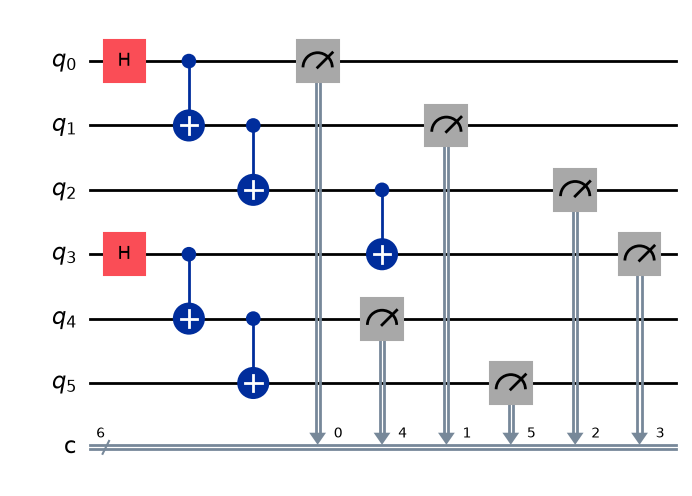

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt


# -------------------------
# Create quantum circuit
# -------------------------

qc = QuantumCircuit(6, 6)

# Module A
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)

# Module B
qc.h(3)
qc.cx(3, 4)
qc.cx(4, 5)

# Inter-module operation
qc.cx(2, 3)

qc.measure(range(6), range(6))

qc.draw("mpl")

In [8]:
# -------------------------
# Simulate
# -------------------------

simulator = AerSimulator()

result = simulator.run(
    qc,
    shots=10_000
).result()

counts = result.get_counts()

print(counts)

{'000000': 2367, '110111': 2591, '001111': 2545, '111000': 2497}


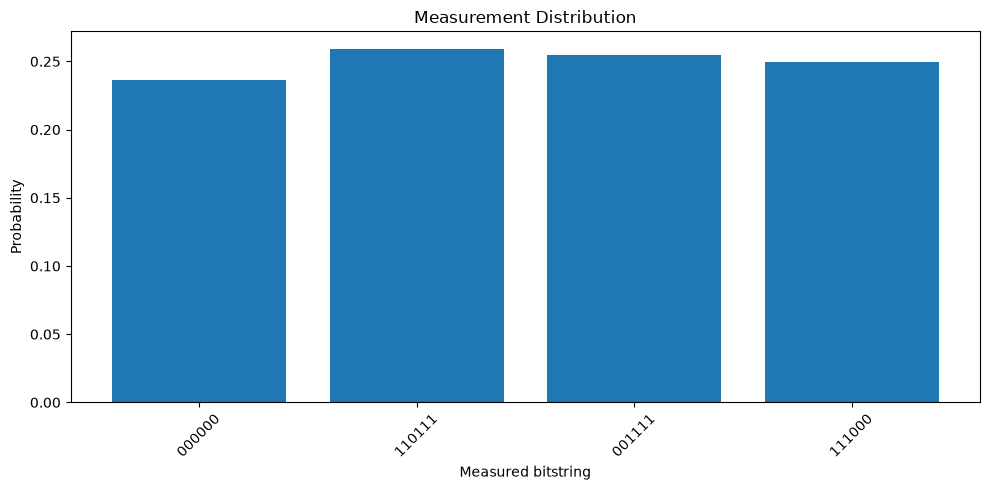

In [9]:
bitstrings = list(counts.keys())

probabilities = [
    counts[x] / 10_000
    for x in bitstrings
]

plt.figure(figsize=(10, 5))

plt.bar(bitstrings, probabilities)

plt.xlabel("Measured bitstring")
plt.ylabel("Probability")
plt.title("Measurement Distribution")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()